# Handwritten Digit Recognition Using Machine Learning, Deep Learning, and Hybrid Approaches

## Import the required Libraries

In [1]:
# import all required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

## Load MNIST dataset

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

print("Original training set shape:", X_train_full.shape, y_train_full.shape)
print("Original test set shape:", X_test.shape, y_test.shape)

Original training set shape: (60000, 28, 28) (60000,)
Original test set shape: (10000, 28, 28) (10000,)


## Data visualization

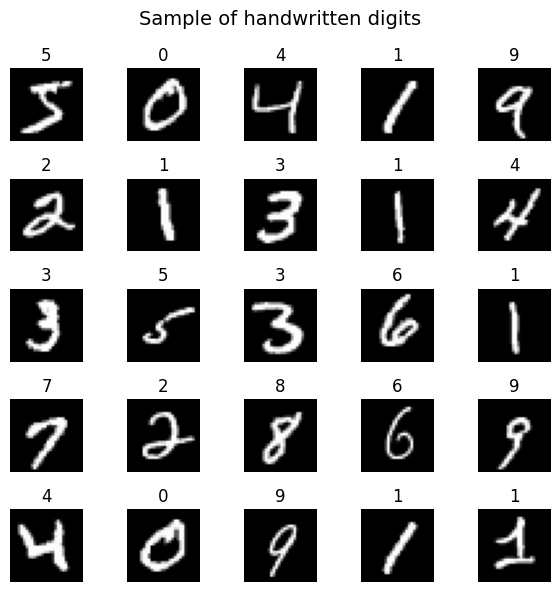

In [3]:
plt.figure(figsize=(6, 6))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    plt.title(y_train_full[i])
    plt.axis('off')

plt.suptitle("Sample of handwritten digits", fontsize=14)
plt.tight_layout()
plt.show()

To understand the dataset, we visualize several handwritten digit samples from the MNIST dataset. The images show that the same digit can be written in many different styles by different people. For example, the digit "1" may appear with different shapes, thickness, or orientation. This variation makes digit recognition a challenging classification problem.

## Class distribution

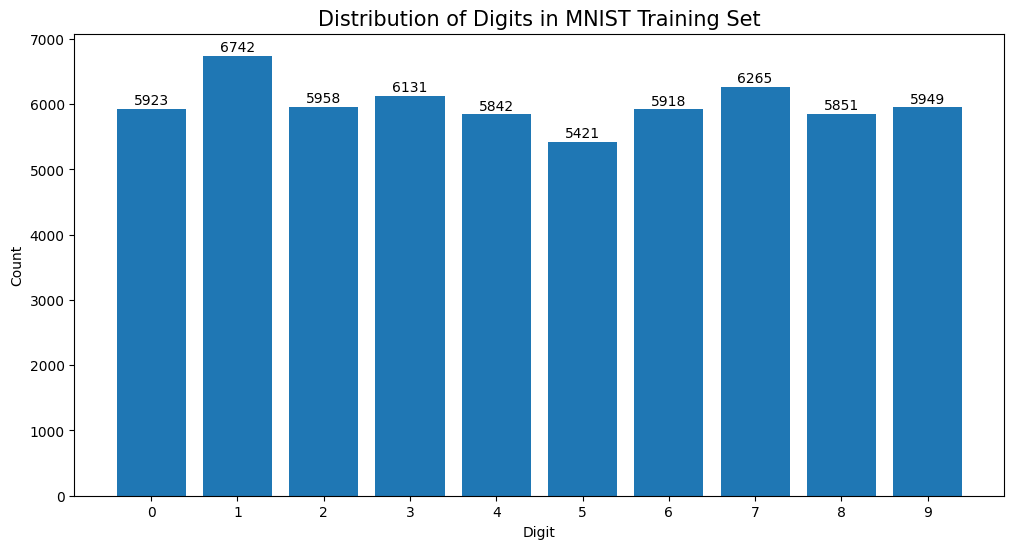

In [4]:
digit_counts = Counter(y_train_full)

digits = list(range(10))
counts = [digit_counts[d] for d in digits]

plt.figure(figsize=(12, 6))
bars = plt.bar(digits, counts)

plt.title("Distribution of Digits in MNIST Training Set", fontsize=15)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.xticks(digits)

for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             str(count), ha='center', va='bottom', fontsize=10)

plt.show()

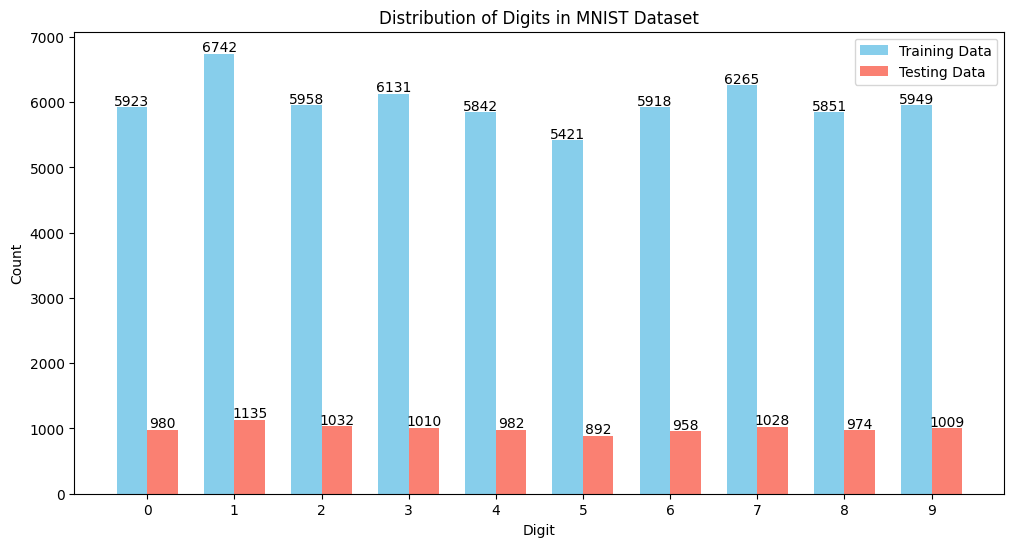

In [5]:
# Count digits
train_counts = Counter(y_train_full)
test_counts = Counter(y_test)

digits = np.arange(10)

train_values = [train_counts[d] for d in digits]
test_values = [test_counts[d] for d in digits]

# bar width
width = 0.35

plt.figure(figsize=(12,6))

# training bars
plt.bar(digits - width/2, train_values, width=width, label="Training Data", color='skyblue')

# testing bars
plt.bar(digits + width/2, test_values, width=width, label="Testing Data", color='salmon')

plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("Distribution of Digits in MNIST Dataset")
plt.xticks(digits)
plt.legend()

# add values above bars
for i in range(len(digits)):
    plt.text(digits[i] - width/2, train_values[i] + 30, str(train_values[i]),
             ha='center', fontsize=10)

    plt.text(digits[i] + width/2, test_values[i] + 30, str(test_values[i]),
             ha='center', fontsize=10)

plt.show()

## Normalize images

In [6]:
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Pixel range after normalization:")
print("Train min:", X_train_full.min(), "Train max:", X_train_full.max())
print("Test min:", X_test.min(), "Test max:", X_test.max())

Pixel range after normalization:
Train min: 0.0 Train max: 1.0
Test min: 0.0 Test max: 1.0


## Split training data into train and validation

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Train set: (48000, 28, 28) (48000,)
Validation set: (12000, 28, 28) (12000,)
Test set: (10000, 28, 28) (10000,)


## Data Preparation

In [8]:
# Flat format for KNN / SVM / MLP
X_train_flat = X_train.reshape(-1, 28*28)
X_val_flat   = X_val.reshape(-1, 28*28)
X_test_flat  = X_test.reshape(-1, 28*28)

print("Flat train shape:", X_train_flat.shape)
print("Flat val shape:", X_val_flat.shape)
print("Flat test shape:", X_test_flat.shape)

# CNN format
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn   = X_val.reshape(-1, 28, 28, 1)
X_test_cnn  = X_test.reshape(-1, 28, 28, 1)

print("\nCNN train shape:", X_train_cnn.shape)
print("CNN val shape:", X_val_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)

# One-hot labels for CNN
y_train_onehot = to_categorical(y_train, 10)
y_val_onehot   = to_categorical(y_val, 10)
y_test_onehot  = to_categorical(y_test, 10)

print("\ny_train_onehot:", y_train_onehot.shape)
print("y_val_onehot:", y_val_onehot.shape)
print("y_test_onehot:", y_test_onehot.shape)

Flat train shape: (48000, 784)
Flat val shape: (12000, 784)
Flat test shape: (10000, 784)

CNN train shape: (48000, 28, 28, 1)
CNN val shape: (12000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)

y_train_onehot: (48000, 10)
y_val_onehot: (12000, 10)
y_test_onehot: (10000, 10)


## Helper Functions for Evaluation

In [9]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    print(f"\n===== {model_name} Classification Report =====")
    print(classification_report(y_true, y_pred, digits=4))

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted'
    )

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


def plot_conf_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

## Traditional Machine learning models

### KNN Model


===== KNN Classification Report =====
              precision    recall  f1-score   support

           0     0.9634    0.9929    0.9779       980
           1     0.9521    0.9974    0.9742      1135
           2     0.9813    0.9641    0.9726      1032
           3     0.9616    0.9673    0.9645      1010
           4     0.9772    0.9613    0.9692       982
           5     0.9640    0.9596    0.9618       892
           6     0.9812    0.9823    0.9817       958
           7     0.9629    0.9601    0.9615      1028
           8     0.9881    0.9353    0.9610       974
           9     0.9585    0.9604    0.9594      1009

    accuracy                         0.9685     10000
   macro avg     0.9690    0.9681    0.9684     10000
weighted avg     0.9687    0.9685    0.9685     10000



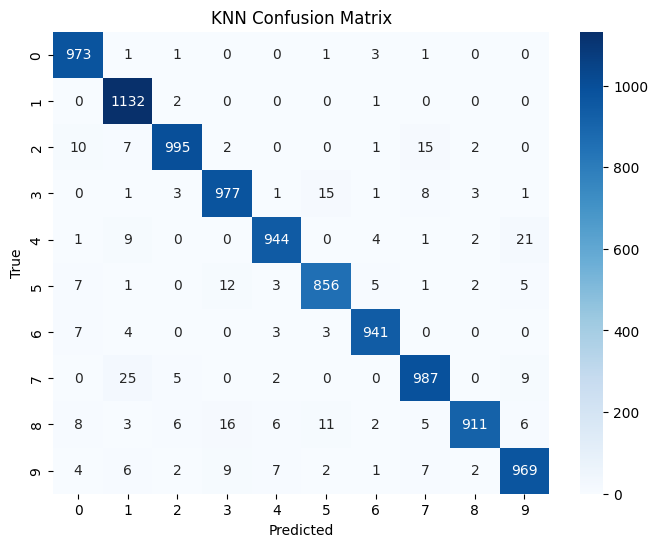

In [10]:
knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(X_train_flat, y_train)

y_val_pred_knn = knn_model.predict(X_val_flat)
y_test_pred_knn = knn_model.predict(X_test_flat)

knn_results = evaluate_model(y_test, y_test_pred_knn, "KNN")
plot_conf_matrix(y_test, y_test_pred_knn, "KNN Confusion Matrix")

### KNN nearest neighbors for a few test samples

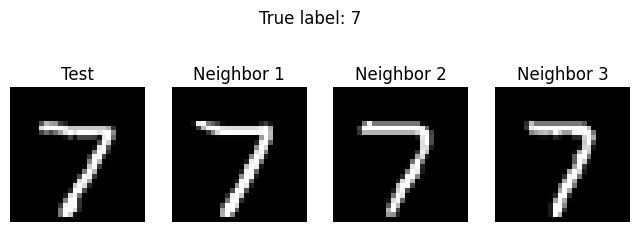

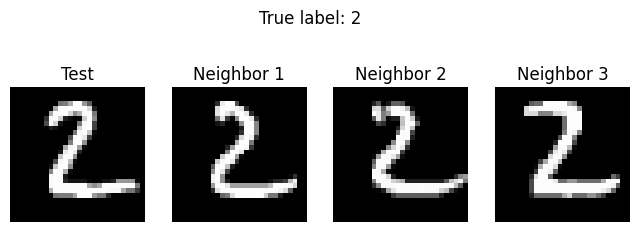

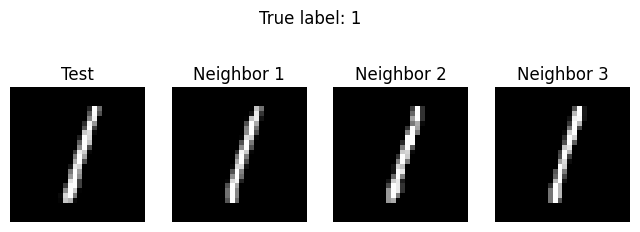

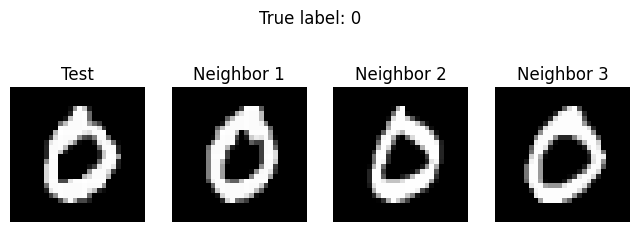

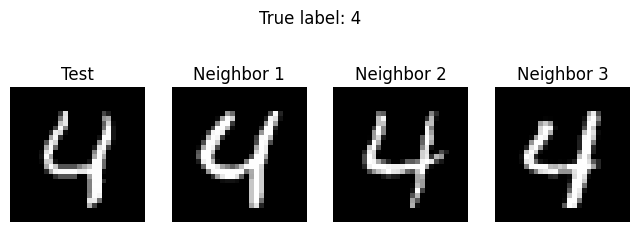

In [11]:
num_examples = 5   # number of test images to visualize

for test_index in range(num_examples):

    distances, indices = knn_model.kneighbors(
        X_test_flat[test_index].reshape(1, -1),
        n_neighbors=3
    )

    plt.figure(figsize=(8,3))

    # Show test image
    plt.subplot(1,4,1)
    plt.imshow(X_test[test_index], cmap='gray')
    plt.title("Test")
    plt.axis("off")

    # Show nearest neighbors
    for i in range(3):
        plt.subplot(1,4,i+2)
        plt.imshow(X_train[indices[0][i]], cmap='gray')
        plt.title(f"Neighbor {i+1}")
        plt.axis("off")

    plt.suptitle(f"True label: {y_test[test_index]}")
    plt.show()

### SVM Model


===== SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9808    0.9929    0.9868       980
           1     0.9869    0.9921    0.9895      1135
           2     0.9769    0.9826    0.9797      1032
           3     0.9765    0.9881    0.9823      1010
           4     0.9827    0.9817    0.9822       982
           5     0.9875    0.9776    0.9825       892
           6     0.9895    0.9833    0.9864       958
           7     0.9765    0.9708    0.9737      1028
           8     0.9814    0.9754    0.9784       974
           9     0.9750    0.9673    0.9711      1009

    accuracy                         0.9813     10000
   macro avg     0.9814    0.9812    0.9813     10000
weighted avg     0.9813    0.9813    0.9813     10000



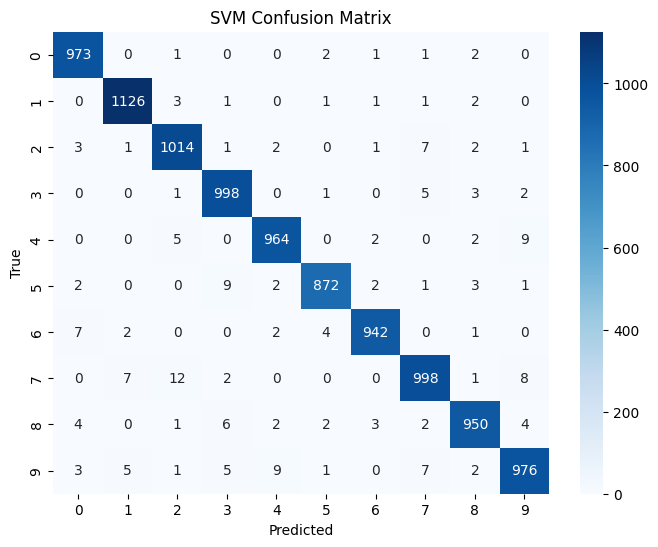

In [12]:
svm_model = SVC(kernel='rbf', C=2.0, gamma='scale')

svm_model.fit(X_train_flat, y_train)

y_val_pred_svm = svm_model.predict(X_val_flat)
y_test_pred_svm = svm_model.predict(X_test_flat)

svm_results = evaluate_model(y_test, y_test_pred_svm, "SVM")
plot_conf_matrix(y_test, y_test_pred_svm, "SVM Confusion Matrix")

## Deep learning models

### Multilayer Perceptron (MLP) Model

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7753 - loss: 0.7225 - val_accuracy: 0.9535 - val_loss: 0.1584
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9425 - loss: 0.1938 - val_accuracy: 0.9637 - val_loss: 0.1213
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9581 - loss: 0.1368 - val_accuracy: 0.9690 - val_loss: 0.1047
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9662 - loss: 0.1088 - val_accuracy: 0.9726 - val_loss: 0.0910
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9734 - loss: 0.0894 - val_accuracy: 0.9755 - val_loss: 0.0782
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9754 - loss: 0.0784 - val_accuracy: 0.9756 - val_loss: 0.0796
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9770 - loss: 0.0739 - val_accuracy: 0.9776 - val_loss: 0.0776
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9812 - loss: 0.0599 - val_accuracy: 0.

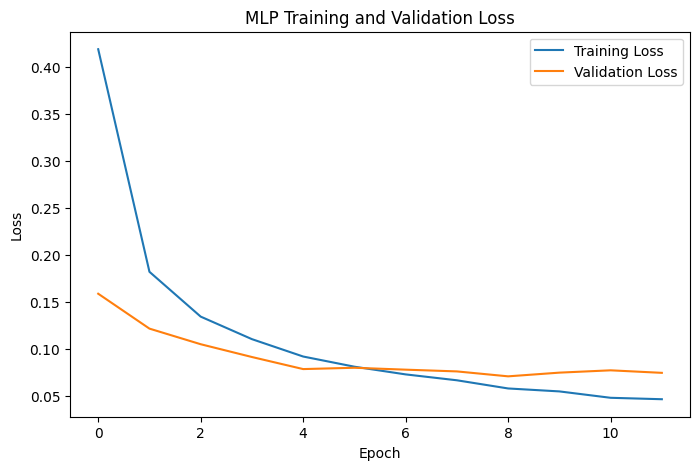

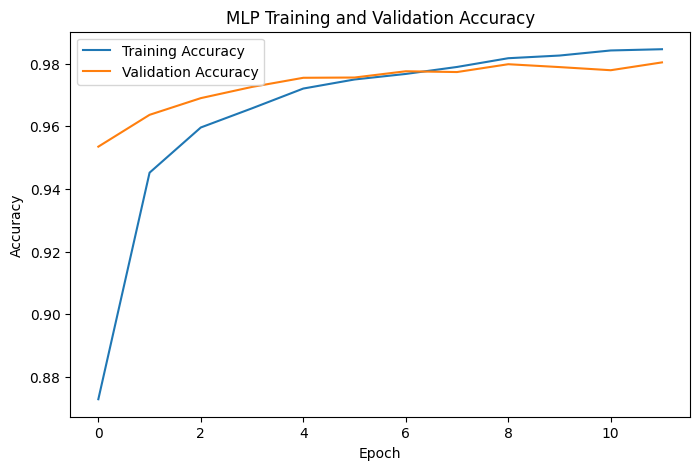

In [13]:
# Early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

mlp_model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mlp_history = mlp_model.fit(
    X_train_flat, y_train_onehot,
    validation_data=(X_val_flat, y_val_onehot),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

# Plot MLP Training and Validation Loss
plt.figure(figsize=(8,5))
plt.plot(mlp_history.history['loss'], label='Training Loss')
plt.plot(mlp_history.history['val_loss'], label='Validation Loss')
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot MLP Training and Validation Accuracy
plt.figure(figsize=(8,5))
plt.plot(mlp_history.history['accuracy'], label='Training Accuracy')
plt.plot(mlp_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [14]:
!apt-get install graphviz -y
!pip install pydot

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.


In [15]:
# Show model summary
mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

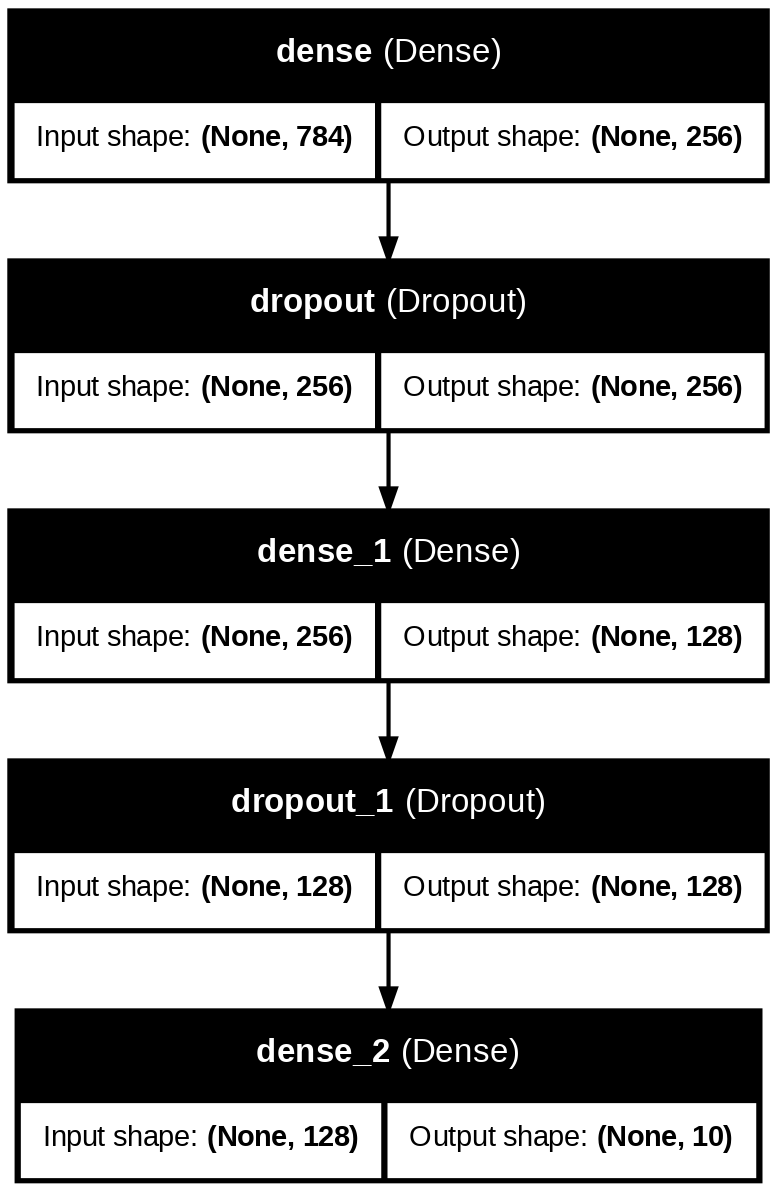

In [16]:
# Import for displaying image
from IPython.display import Image, display

# Save architecture diagram
plot_model(
    mlp_model,
    to_file="mlp_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=150
)

# Display architecture diagram
display(Image("mlp_architecture.png"))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step

===== MLP Classification Report =====
              precision    recall  f1-score   support

           0     0.9789    0.9918    0.9853       980
           1     0.9886    0.9930    0.9908      1135
           2     0.9769    0.9835    0.9802      1032
           3     0.9755    0.9861    0.9808      1010
           4     0.9815    0.9715    0.9765       982
           5     0.9898    0.9787    0.9842       892
           6     0.9832    0.9802    0.9817       958
           7     0.9749    0.9825    0.9787      1028
           8     0.9843    0.9651    0.9746       974
           9     0.9742    0.9722    0.9732      1009

    accuracy                         0.9807     10000
   macro avg     0.9808    0.9805    0.9806     10000
weighted avg     0.9807    0.9807    0.9807     10000



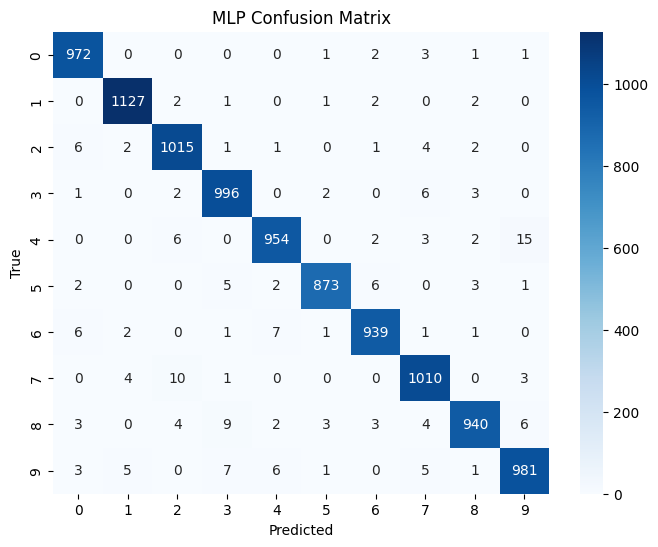

In [17]:
# TEST MLP
y_test_pred_mlp = np.argmax(mlp_model.predict(X_test_flat), axis=1)

mlp_results = evaluate_model(y_test, y_test_pred_mlp, "MLP")
plot_conf_matrix(y_test, y_test_pred_mlp, "MLP Confusion Matrix")

### CNN Model

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.7762 - loss: 0.7007 - val_accuracy: 0.9759 - val_loss: 0.0864
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9661 - loss: 0.1190 - val_accuracy: 0.9829 - val_loss: 0.0569
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9771 - loss: 0.0785 - val_accuracy: 0.9846 - val_loss: 0.0495
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9811 - loss: 0.0630 - val_accuracy: 0.9869 - val_loss: 0.0440
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9847 - loss: 0.0513 - val_accuracy: 0.9874 - val_loss: 0.0430
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9853 - loss: 0.0481 - val_accuracy: 0.9864 - val_loss: 0.0464
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9875 - loss: 0.0409 - val_accuracy: 0.9880 - val_loss: 0.0392
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9891 - loss: 0.0360 - val_accuracy: 

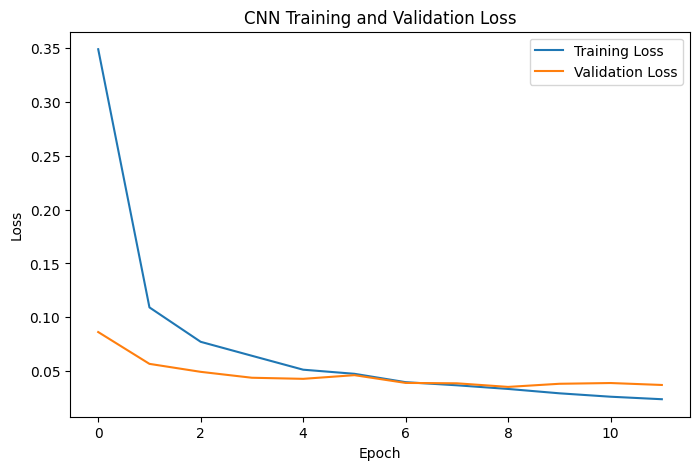

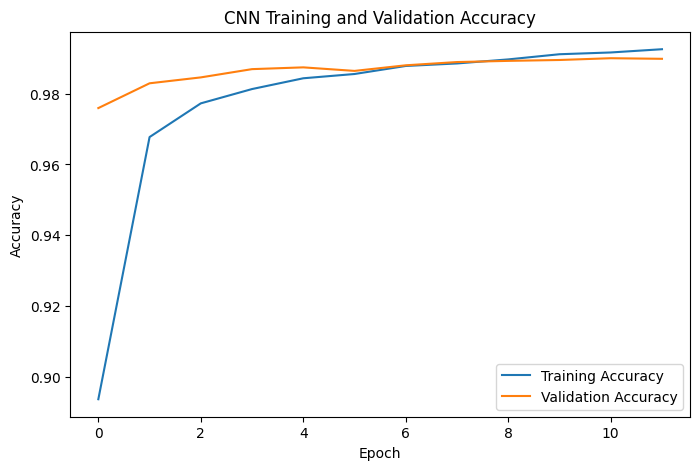

In [18]:
# Early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

cnn_model = Sequential([
    Input(shape=(28,28,1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    X_train_cnn, y_train_onehot,
    validation_data=(X_val_cnn, y_val_onehot),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

# Plot CNN Loss
plt.figure(figsize=(8,5))
plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot CNN Training and Validation Accuracy
plt.figure(figsize=(8,5))
plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [19]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

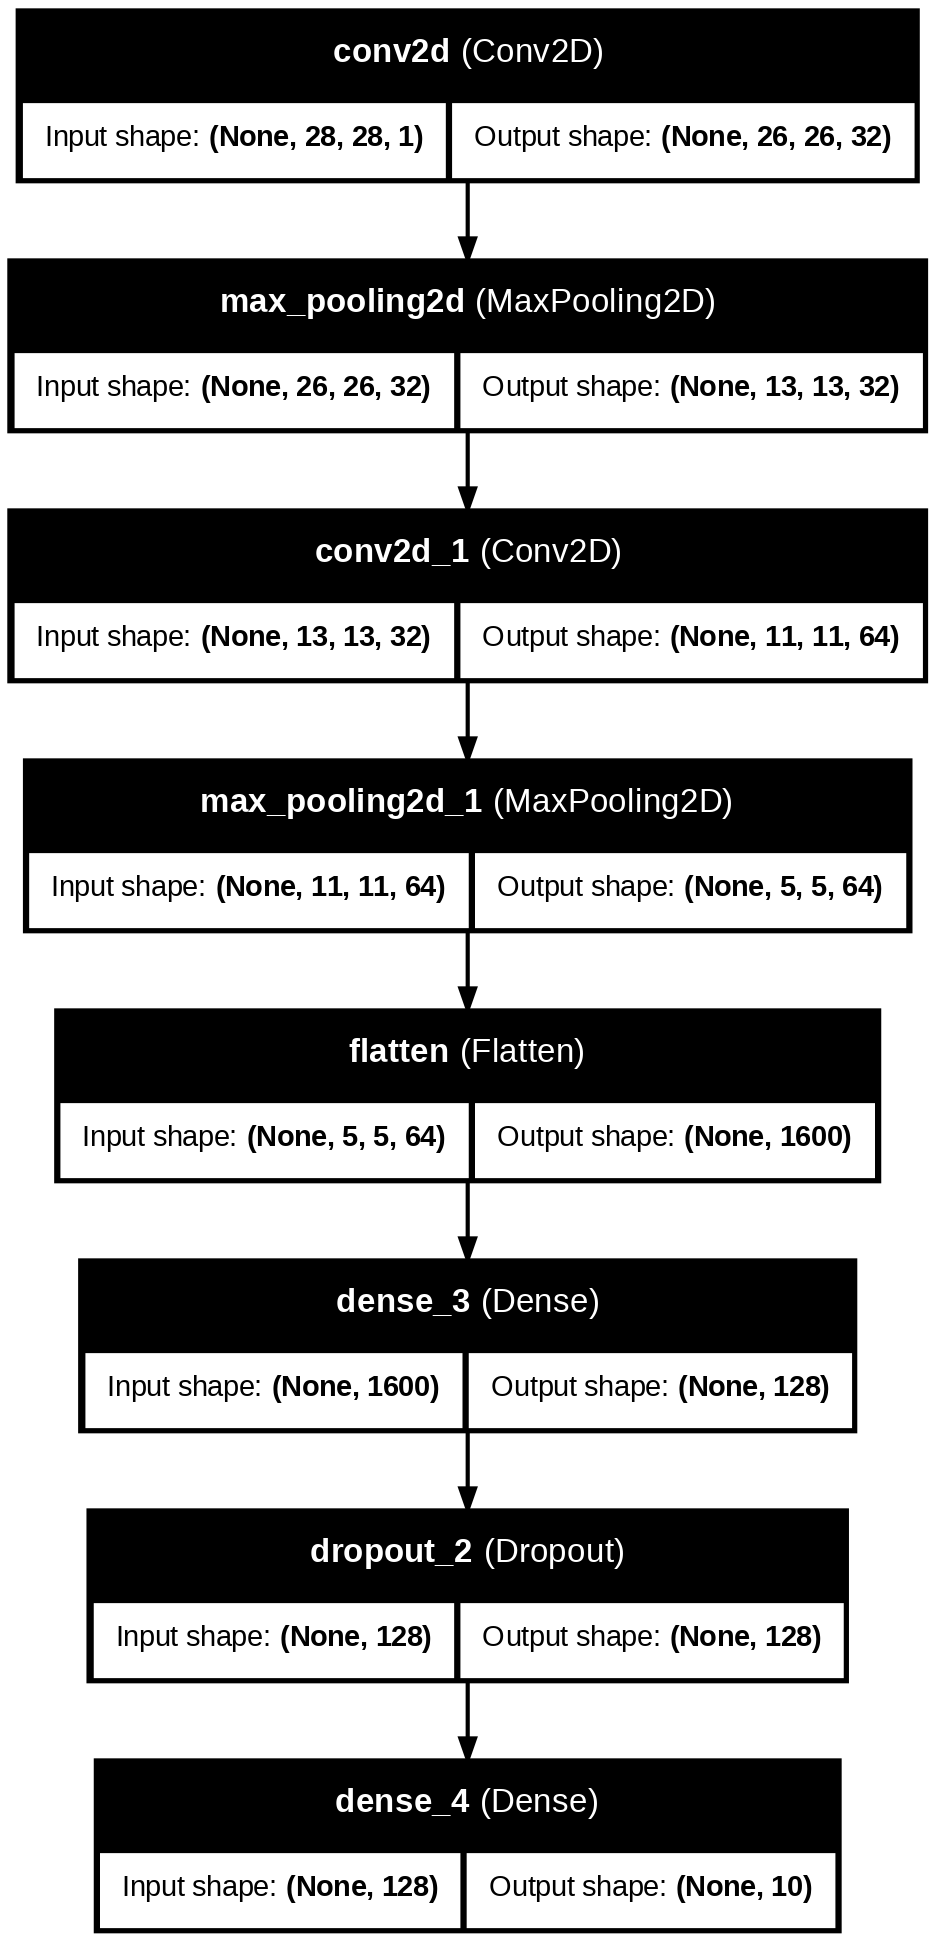

In [20]:
# Save CNN architecture diagram
plot_model(
    cnn_model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=150
)

# Display architecture diagram
display(Image("cnn_architecture.png"))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

===== CNN Classification Report =====
              precision    recall  f1-score   support

           0     0.9899    0.9980    0.9939       980
           1     0.9939    0.9991    0.9965      1135
           2     0.9922    0.9922    0.9922      1032
           3     0.9921    0.9931    0.9926      1010
           4     0.9949    0.9929    0.9939       982
           5     0.9855    0.9910    0.9883       892
           6     0.9989    0.9875    0.9932       958
           7     0.9884    0.9922    0.9903      1028
           8     0.9938    0.9815    0.9876       974
           9     0.9891    0.9901    0.9896      1009

    accuracy                         0.9919     10000
   macro avg     0.9919    0.9918    0.9918     10000
weighted avg     0.9919    0.9919    0.9919     10000



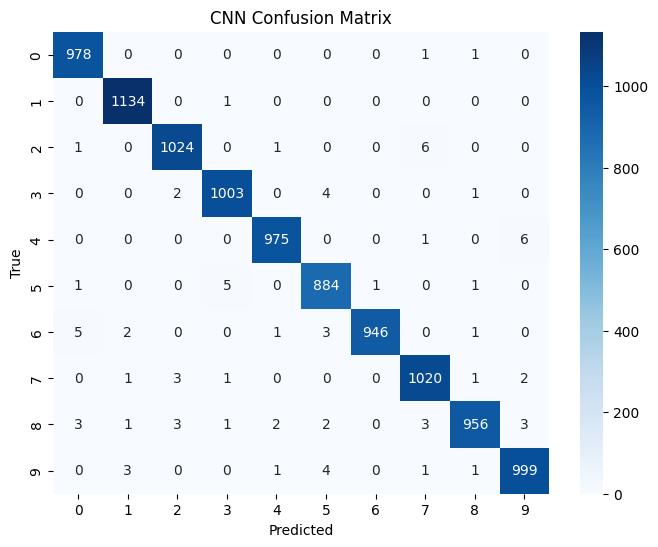

In [21]:
# TEST CNN
y_test_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)

cnn_results = evaluate_model(y_test, y_test_pred_cnn, "CNN")
plot_conf_matrix(y_test, y_test_pred_cnn, "CNN Confusion Matrix")

## Hybrid Model

### KNN-SVM

KNN trained.
Training binary SVM for classes 0 vs 1
Training binary SVM for classes 0 vs 2
Training binary SVM for classes 0 vs 3
Training binary SVM for classes 0 vs 4
Training binary SVM for classes 0 vs 5
Training binary SVM for classes 0 vs 6
Training binary SVM for classes 0 vs 7
Training binary SVM for classes 0 vs 8
Training binary SVM for classes 0 vs 9
Training binary SVM for classes 1 vs 2
Training binary SVM for classes 1 vs 3
Training binary SVM for classes 1 vs 4
Training binary SVM for classes 1 vs 5
Training binary SVM for classes 1 vs 6
Training binary SVM for classes 1 vs 7
Training binary SVM for classes 1 vs 8
Training binary SVM for classes 1 vs 9
Training binary SVM for classes 2 vs 3
Training binary SVM for classes 2 vs 4
Training binary SVM for classes 2 vs 5
Training binary SVM for classes 2 vs 6
Training binary SVM for classes 2 vs 7
Training binary SVM for classes 2 vs 8
Training binary SVM for classes 2 vs 9
Training binary SVM for classes 3 vs 4
Training bin

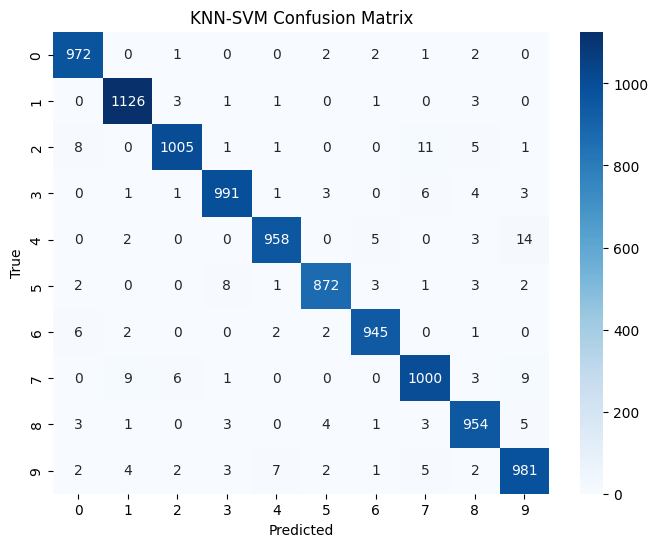

In [22]:
from itertools import combinations
from collections import Counter

# TRAIN KNN

knn_k = 3
top_n_candidates = 3   # KNN will shortlist top 3 classes

knn_model = KNeighborsClassifier(n_neighbors=knn_k)
knn_model.fit(X_train_flat, y_train)

print("KNN trained.")


# TRAIN PAIRWISE SVMs FOR ALL CLASS PAIRS

pairwise_svms = {}

classes = np.unique(y_train)

for c1, c2 in combinations(classes, 2):
    print(f"Training binary SVM for classes {c1} vs {c2}")

    mask = (y_train == c1) | (y_train == c2)
    X_pair = X_train_flat[mask]
    y_pair = y_train[mask]

    svm = SVC(kernel='rbf', C=2.0, gamma='scale')
    svm.fit(X_pair, y_pair)

    pairwise_svms[(c1, c2)] = svm

print("All pairwise SVMs trained.")


def predict_knn_svm_hybrid(X):
    """
    Predict using:
    1. KNN shortlist
    2. Pairwise SVM voting among shortlisted classes
    """
    final_predictions = []


    knn_probs = knn_model.predict_proba(X)
    knn_classes = knn_model.classes_

    for i in range(X.shape[0]):
        sample = X[i].reshape(1, -1)


        probs = knn_probs[i]
        top_indices = np.argsort(probs)[-top_n_candidates:][::-1]
        candidate_classes = knn_classes[top_indices]

        if len(candidate_classes) == 1:
            final_predictions.append(candidate_classes[0])
            continue


        votes = []

        for c1, c2 in combinations(candidate_classes, 2):
            pair = tuple(sorted((c1, c2)))
            svm = pairwise_svms[pair]
            pred = svm.predict(sample)[0]
            votes.append(pred)


        vote_counts = Counter(votes)
        final_class = vote_counts.most_common(1)[0][0]

        final_predictions.append(final_class)

    return np.array(final_predictions)

# VALIDATION PREDICTION

y_val_pred_knn_svm = predict_knn_svm_hybrid(X_val_flat)
val_acc = accuracy_score(y_val, y_val_pred_knn_svm)

print("\nValidation Accuracy of KNN-SVM Hybrid:", val_acc)

# TEST PREDICTION

y_test_pred_knn_svm = predict_knn_svm_hybrid(X_test_flat)
test_acc = accuracy_score(y_test, y_test_pred_knn_svm)

print("Test Accuracy of KNN-SVM Hybrid:", test_acc)


# EVALUATE

knn_svm_results = evaluate_model(y_test, y_test_pred_knn_svm, "KNN-SVM")
plot_conf_matrix(y_test, y_test_pred_knn_svm, "KNN-SVM Confusion Matrix")

### CNN-SVM

In [23]:
# CNN feature extractor for CNN-SVM

cnn_svm_base_input = Input(shape=(28, 28, 1))

x = Conv2D(32, (3, 3), activation='relu')(cnn_svm_base_input)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)

x = Flatten()(x)
feature_layer = Dense(128, activation='relu', name='feature_layer')(x)
x = Dropout(0.5)(feature_layer)
output_layer = Dense(10, activation='softmax')(x)

cnn_svm_base_model = Model(inputs=cnn_svm_base_input, outputs=output_layer)

cnn_svm_base_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_svm_base_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_layer (Dense)           │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7701 - loss: 0.7246 - val_accuracy: 0.9762 - val_loss: 0.0817
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9623 - loss: 0.1274 - val_accuracy: 0.9831 - val_loss: 0.0582
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9761 - loss: 0.0820 - val_accuracy: 0.9862 - val_loss: 0.0476
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9805 - loss: 0.0665 - val_accuracy: 0.9873 - val_loss: 0.0437
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9832 - loss: 0.0565 - val_accuracy: 0.9879 - val_loss: 0.0415
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9846 - loss: 0.0487 - val_accuracy: 0.9890 - val_loss: 0.0392
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9869 - loss: 0.0416 - val_accuracy: 0.9880 - val_loss: 0.0358
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9885 - loss: 0.0369 - val_accuracy: 0.

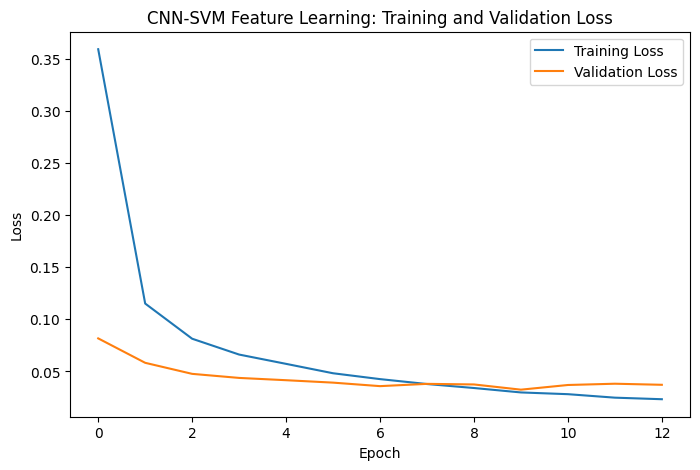

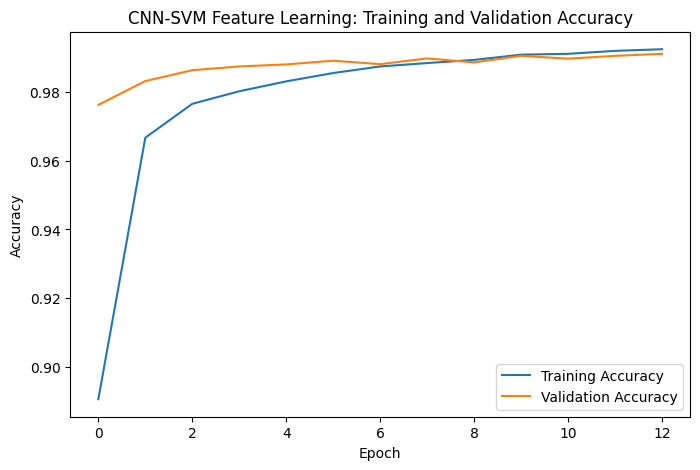

In [24]:
# Early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)


# Train SVM on CNN Features

cnn_svm_history = cnn_svm_base_model.fit(
    X_train_cnn, y_train_onehot,
    validation_data=(X_val_cnn, y_val_onehot),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

# Plot training and validation loss
plt.figure(figsize=(8,5))
plt.plot(cnn_svm_history.history['loss'], label='Training Loss')
plt.plot(cnn_svm_history.history['val_loss'], label='Validation Loss')
plt.title("CNN-SVM Feature Learning: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8,5))
plt.plot(cnn_svm_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_svm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("CNN-SVM Feature Learning: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [25]:
# Create feature extractor model

feature_extractor = Model(
    inputs=cnn_svm_base_model.input,
    outputs=cnn_svm_base_model.get_layer('feature_layer').output
)

X_train_features = feature_extractor.predict(X_train_cnn, verbose=0)
X_val_features = feature_extractor.predict(X_val_cnn, verbose=0)
X_test_features = feature_extractor.predict(X_test_cnn, verbose=0)


print("Train feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Test feature shape:", X_test_features.shape)


Train feature shape: (48000, 128)
Validation feature shape: (12000, 128)
Test feature shape: (10000, 128)



===== CNN-SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9909    0.9949    0.9929       980
           1     0.9947    1.0000    0.9974      1135
           2     0.9923    0.9932    0.9927      1032
           3     0.9941    0.9941    0.9941      1010
           4     0.9939    0.9939    0.9939       982
           5     0.9899    0.9910    0.9905       892
           6     0.9979    0.9906    0.9942       958
           7     0.9903    0.9883    0.9893      1028
           8     0.9908    0.9938    0.9923       974
           9     0.9930    0.9871    0.9901      1009

    accuracy                         0.9928     10000
   macro avg     0.9928    0.9927    0.9927     10000
weighted avg     0.9928    0.9928    0.9928     10000



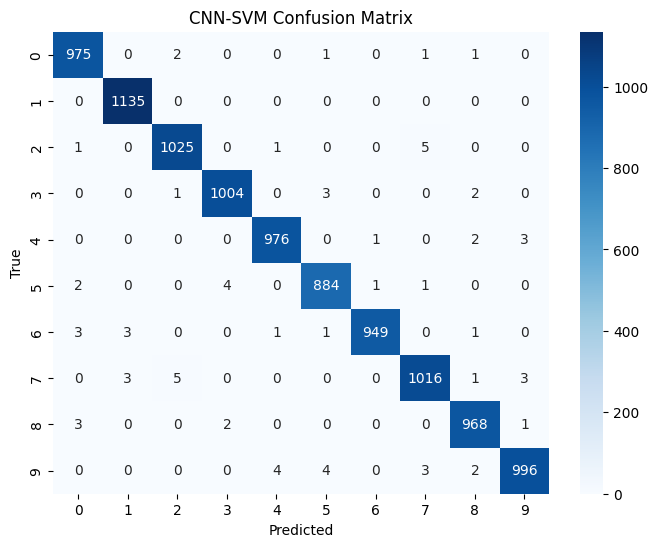

In [26]:
# Train SVM on CNN features
cnn_svm_classifier = SVC(kernel='rbf', C=2.0, gamma='scale')

cnn_svm_classifier.fit(X_train_features, y_train)

# Predict and evaluate CNN-SVM
y_val_pred_cnn_svm = cnn_svm_classifier.predict(X_val_features)
y_test_pred_cnn_svm = cnn_svm_classifier.predict(X_test_features)

cnn_svm_results = evaluate_model(y_test, y_test_pred_cnn_svm, "CNN-SVM")
plot_conf_matrix(y_test, y_test_pred_cnn_svm, "CNN-SVM Confusion Matrix")

## Model Comparison

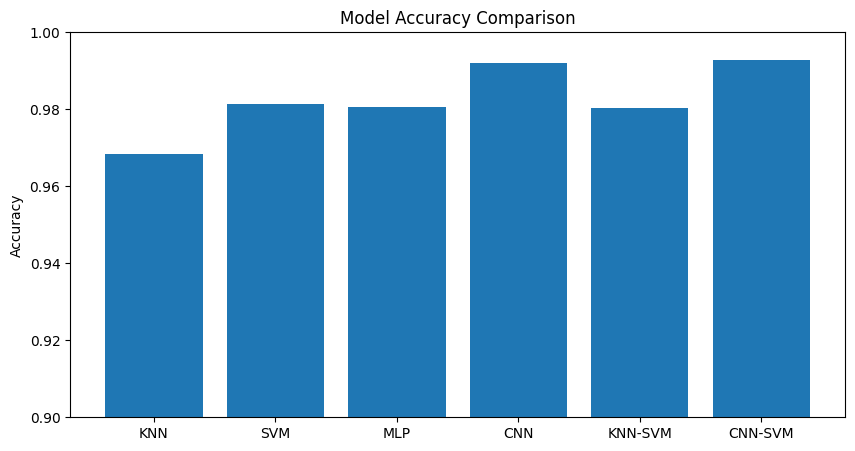

In [27]:
# Collect All Results in a Table

results_df = pd.DataFrame([
    knn_results,
    svm_results,
    mlp_results,
    cnn_results,
    knn_svm_results,
    cnn_svm_results

])

results_df

# Plot Accuracy Comparison
plt.figure(figsize=(10,5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.9, 1.0)
plt.show()

<Figure size 1000x600 with 0 Axes>

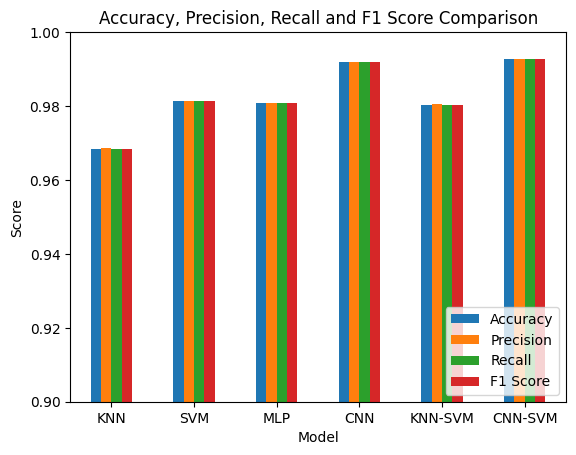

In [28]:
# Plot Precision / Recall / F1 Comparison
metrics_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]]

plt.figure(figsize=(10,6))

metrics_df.plot(kind='bar')

plt.title("Accuracy, Precision, Recall and F1 Score Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0.9, 1.0)
plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.show()

## Heatmap for Accuracy, Precision, Recall, F1 Score

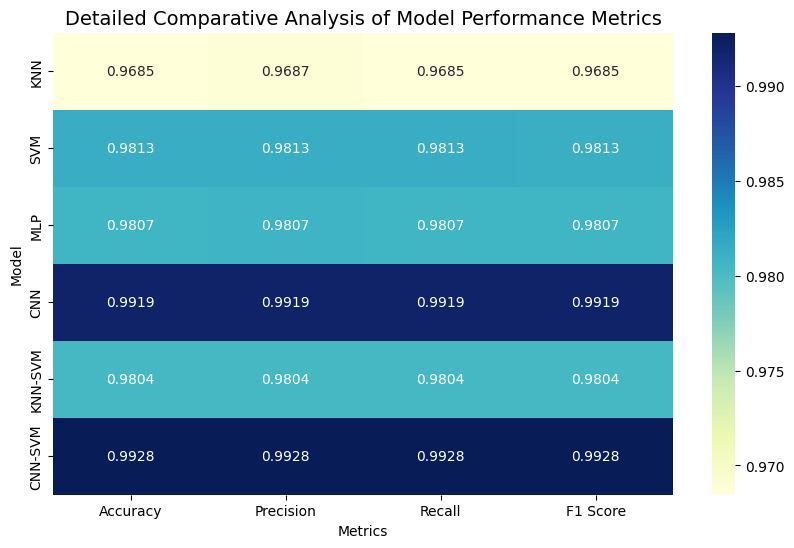

In [29]:
heatmap_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]]

plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("Detailed Comparative Analysis of Model Performance Metrics", fontsize=14)
plt.xlabel("Metrics")
plt.ylabel("Model")
plt.show()

In [38]:
# Per-Class Reports as Tables

def get_classification_report_df(y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    return pd.DataFrame(report).transpose()

knn_report_df = get_classification_report_df(y_test, y_test_pred_knn)
svm_report_df = get_classification_report_df(y_test, y_test_pred_svm)
mlp_report_df = get_classification_report_df(y_test, y_test_pred_mlp)
cnn_report_df = get_classification_report_df(y_test, y_test_pred_cnn)
cnn_svm_report_df = get_classification_report_df(y_test, y_test_pred_cnn_svm)
knn_svm_report_df = get_classification_report_df(y_test, y_test_pred_knn_svm)

print("KNN report:")
display(knn_report_df)
print("\nSVM report:")
display(svm_report_df)
print("\nMLP report:")
display(mlp_report_df)
print("\nCNN report:")
display(cnn_report_df)
print("\nCNN-SVM report:")
display(cnn_svm_report_df)
print("\nKNN-SVM report:")
display(knn_svm_report_df)

KNN report:


,precision,recall,f1-score,support
0,0.963366,0.992857,0.977889,980.0000
1,0.952061,0.997357,0.974182,1135.0000
2,0.981262,0.964147,0.972630,1032.0000
3,0.961614,0.967327,0.964462,1010.0000
4,0.977226,0.961303,0.969199,982.0000
5,0.963964,0.959641,0.961798,892.0000
6,0.981230,0.982255,0.981742,958.0000
7,0.962927,0.960117,0.961520,1028.0000
8,0.988069,0.935318,0.960970,974.0000
9,0.958457,0.960357,0.959406,1009.0000



SVM report:


,precision,recall,f1-score,support
0,0.980847,0.992857,0.986815,980.0000
1,0.986854,0.992070,0.989455,1135.0000
2,0.976879,0.982558,0.979710,1032.0000
3,0.976517,0.988119,0.982283,1010.0000
4,0.982671,0.981670,0.982170,982.0000
5,0.987542,0.977578,0.982535,892.0000
6,0.989496,0.983299,0.986387,958.0000
7,0.976517,0.970817,0.973659,1028.0000
8,0.981405,0.975359,0.978373,974.0000
9,0.975025,0.967294,0.971144,1009.0000



MLP report:


...

,precision,recall,f1-score,support
0,0.989879,0.997959,0.993902,980.0000
1,0.993865,0.999119,0.996485,1135.0000
2,0.992248,0.992248,0.992248,1032.0000
3,0.992087,0.993069,0.992578,1010.0000
4,0.994898,0.992872,0.993884,982.0000
5,0.985507,0.991031,0.988262,892.0000
6,0.998944,0.987474,0.993176,958.0000
7,0.988372,0.992218,0.990291,1028.0000
8,0.993763,0.981520,0.987603,974.0000
9,0.989109,0.990089,0.989599,1009.0000



CNN-SVM report:


,precision,recall,f1-score,support
0,0.990854,0.994898,0.992872,980.0000
1,0.994741,1.000000,0.997364,1135.0000
2,0.992256,0.993217,0.992736,1032.0000
3,0.994059,0.994059,0.994059,1010.0000
4,0.993890,0.993890,0.993890,982.0000
5,0.989922,0.991031,0.990476,892.0000
6,0.997897,0.990605,0.994238,958.0000
7,0.990253,0.988327,0.989289,1028.0000
8,0.990788,0.993840,0.992312,974.0000
9,0.993021,0.987116,0.990060,1009.0000



KNN-SVM report:


,precision,recall,f1-score,support
0,0.978852,0.991837,0.985302,980.0000
1,0.983406,0.992070,0.987719,1135.0000
2,0.987230,0.973837,0.980488,1032.0000
3,0.983135,0.981188,0.982161,1010.0000
4,0.986612,0.975560,0.981055,982.0000
5,0.985311,0.977578,0.981429,892.0000
6,0.986430,0.986430,0.986430,958.0000
7,0.973710,0.972763,0.973236,1028.0000
8,0.973469,0.979466,0.976459,974.0000
9,0.966502,0.972250,0.969368,1009.0000


In [39]:
sorted_results = results_df.sort_values(by="Accuracy", ascending=False)
display(sorted_results)

,Model,Accuracy,Precision,Recall,F1 Score
5,CNN-SVM,0.9928,0.992804,0.9928,0.992798
3,CNN,0.9919,0.991916,0.9919,0.991897
1,SVM,0.9813,0.981308,0.9813,0.981289
2,MLP,0.9807,0.980728,0.9807,0.980689
4,KNN-SVM,0.9804,0.980431,0.9804,0.980398
0,KNN,0.9685,0.968744,0.9685,0.968454


## Save The Model

In [40]:
# Save CNN part of CNN-SVM
cnn_svm_base_model.save("cnn_svm_feature_extractor.keras")

# Save SVM part of CNN-SVM
import joblib
joblib.dump(cnn_svm_classifier, "cnn_svm_classifier.pkl")

print("CNN-SVM model files saved successfully.")

CNN-SVM model files saved successfully.


## Load the saved files

In [41]:
from tensorflow.keras.models import load_model, Model
import joblib

loaded_cnn = load_model("cnn_svm_feature_extractor.keras")
loaded_svm = joblib.load("cnn_svm_classifier.pkl")

print("Both saved files loaded successfully.")

Both saved files loaded successfully.


In [42]:
loaded_feature_extractor = Model(
    inputs=loaded_cnn.input,
    outputs=loaded_cnn.get_layer("feature_layer").output
)

print("Feature extractor recreated successfully.")

Feature extractor recreated successfully.


In [43]:
X_test_features_loaded = loaded_feature_extractor.predict(X_test_cnn[:10], verbose=0)
y_pred_loaded = loaded_svm.predict(X_test_features_loaded)

print("Predicted:", y_pred_loaded)
print("True labels:", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
True labels: [7 2 1 0 4 1 4 9 5 9]



===== Loaded CNN-SVM Classification Report =====
              precision    recall  f1-score   support

           0     0.9909    0.9949    0.9929       980
           1     0.9947    1.0000    0.9974      1135
           2     0.9923    0.9932    0.9927      1032
           3     0.9941    0.9941    0.9941      1010
           4     0.9939    0.9939    0.9939       982
           5     0.9899    0.9910    0.9905       892
           6     0.9979    0.9906    0.9942       958
           7     0.9903    0.9883    0.9893      1028
           8     0.9908    0.9938    0.9923       974
           9     0.9930    0.9871    0.9901      1009

    accuracy                         0.9928     10000
   macro avg     0.9928    0.9927    0.9927     10000
weighted avg     0.9928    0.9928    0.9928     10000



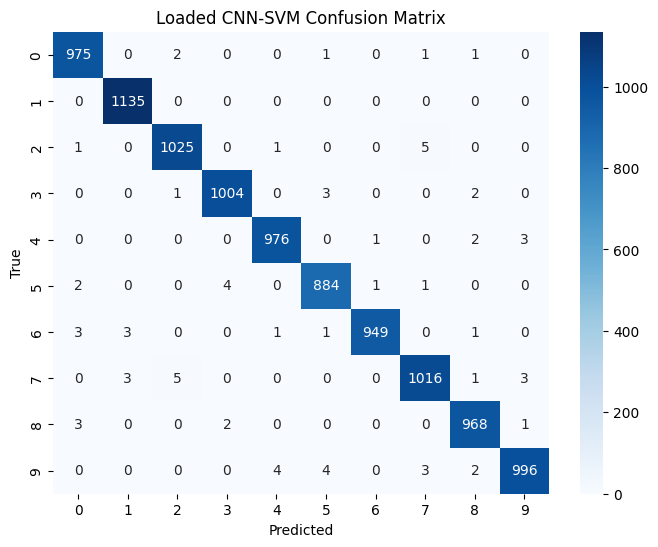

In [44]:
X_test_features_all = loaded_feature_extractor.predict(X_test_cnn, verbose=0)
y_test_pred_loaded = loaded_svm.predict(X_test_features_all)

loaded_results = evaluate_model(y_test, y_test_pred_loaded, "Loaded CNN-SVM")
plot_conf_matrix(y_test, y_test_pred_loaded, "Loaded CNN-SVM Confusion Matrix")

## Load Image

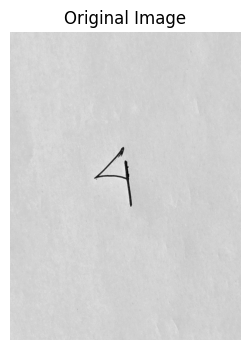

In [45]:
from PIL import Image
import cv2

image_path = "Four.jpg"

img = Image.open(image_path).convert("L")
img_array = np.array(img)

plt.figure(figsize=(4,4))
plt.imshow(img_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

## Prediction before preprocessing

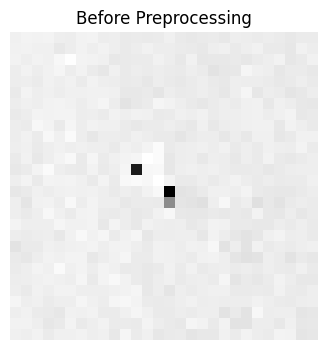

Prediction BEFORE preprocessing: 0


In [53]:
# Directly resize original image to MNIST size
raw_resized = cv2.resize(img_array, (28,28))

plt.figure(figsize=(4,4))
plt.imshow(raw_resized, cmap="gray")
plt.title("Before Preprocessing")
plt.axis("off")
plt.show()

# Normalize
raw_resized = raw_resized.astype("float32") / 255.0
raw_input = raw_resized.reshape(1,28,28,1)

# Predict
raw_features = loaded_feature_extractor.predict(raw_input, verbose=0)
raw_prediction = loaded_svm.predict(raw_features)[0]

print("Prediction BEFORE preprocessing:", raw_prediction)

## Prediction AFTER preprocessing

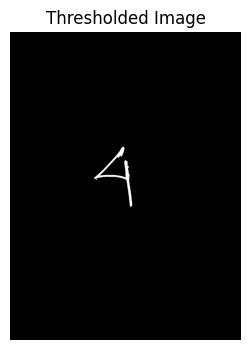

In [54]:
# Blur a little to reduce noise
blurred = cv2.GaussianBlur(img_array, (5,5), 0)

# Binary inverse threshold
_, thresh = cv2.threshold(blurred, 150, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(4,4))
plt.imshow(thresh, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

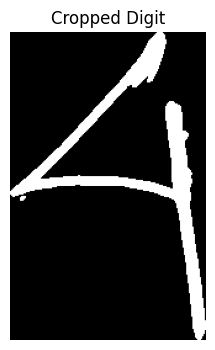

In [55]:
coords = cv2.findNonZero(thresh)

x, y, w, h = cv2.boundingRect(coords)
cropped = thresh[y:y+h, x:x+w]

plt.figure(figsize=(4,4))
plt.imshow(cropped, cmap="gray")
plt.title("Cropped Digit")
plt.axis("off")
plt.show()

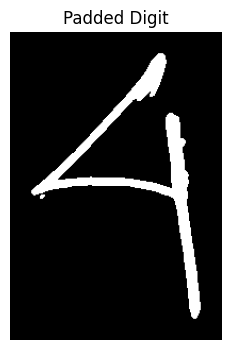

In [56]:
padded = np.pad(cropped, ((20,20), (20,20)), mode='constant', constant_values=0)

plt.figure(figsize=(4,4))
plt.imshow(padded, cmap="gray")
plt.title("Padded Digit")
plt.axis("off")
plt.show()

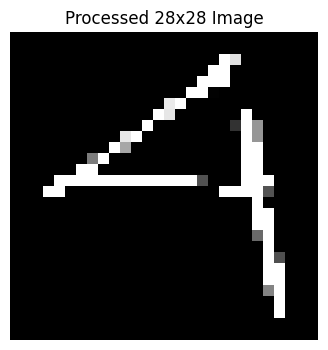

In [57]:
processed = cv2.resize(padded, (28, 28))

plt.figure(figsize=(4,4))
plt.imshow(processed, cmap="gray")
plt.title("Processed 28x28 Image")
plt.axis("off")
plt.show()

In [58]:
processed = processed.astype("float32") / 255.0
img_input = processed.reshape(1, 28, 28, 1)

print("Input shape:", img_input.shape)

Input shape: (1, 28, 28, 1)


In [59]:
img_features = loaded_feature_extractor.predict(img_input, verbose=0)
predicted_digit = loaded_svm.predict(img_features)[0]

print("Predicted digit:", predicted_digit)

Predicted digit: 4


To demonstrate the importance of preprocessing, predictions were generated using both the raw input image and the processed MNIST-style image. When the raw image was directly resized to 28×28 without preprocessing, the model often produced incorrect predictions due to background noise, scale differences, and poor alignment with the MNIST training distribution. After applying preprocessing steps such as thresholding, cropping, padding, and normalization, the digit representation became closer to the MNIST format, resulting in significantly improved prediction accuracy.

## Robustness analysis

In [60]:
# Add Gaussian noise
def add_gaussian_noise(images, mean=0, std=0.2):
    noisy = images + np.random.normal(mean, std, images.shape)
    noisy = np.clip(noisy, 0, 1)
    return noisy

# Rotate images
def rotate_images(images, angle=10):
    rotated_images = []
    for img in images:
        h, w = img.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(img, M, (w, h), borderValue=0)
        rotated_images.append(rotated)
    return np.array(rotated_images)

# Shift images
def shift_images(images, shift_x=2, shift_y=2):
    shifted_images = []
    for img in images:
        M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
        shifted = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), borderValue=0)
        shifted_images.append(shifted)
    return np.array(shifted_images)

In [61]:
# Original test images
X_test_base = X_test.copy()

# Perturbed versions
X_test_noisy = add_gaussian_noise(X_test_base, std=0.15)
X_test_rotated = rotate_images(X_test_base, angle=10)
X_test_shifted = shift_images(X_test_base, shift_x=2, shift_y=2)

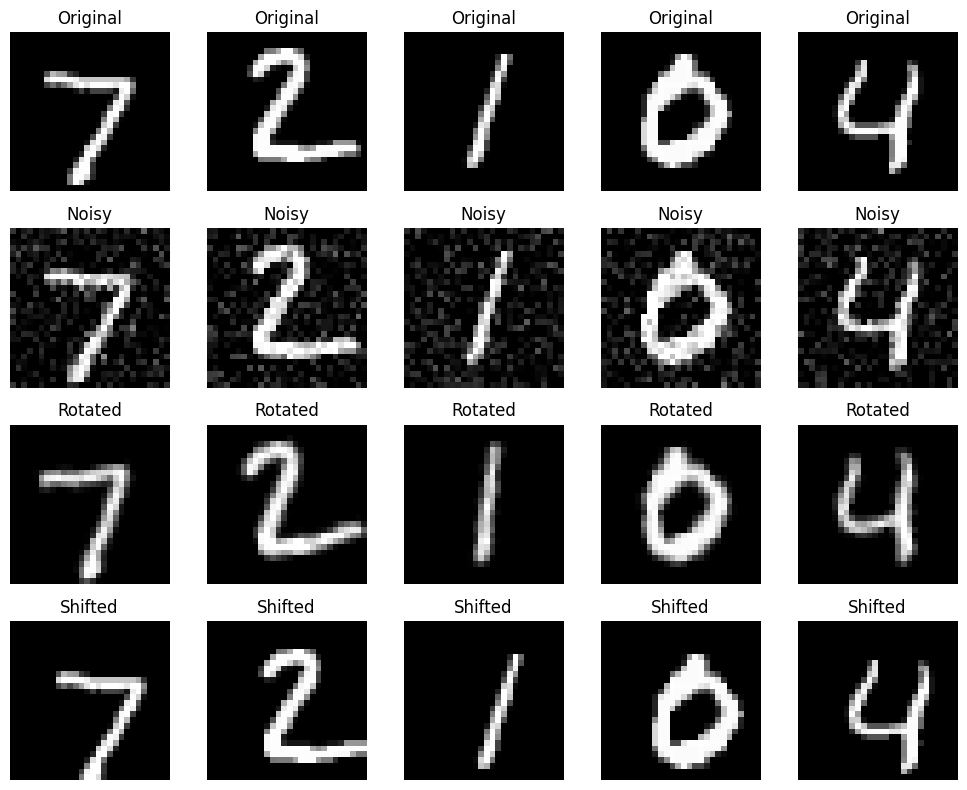

In [62]:
# Visualize a few examples
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i in range(5):
    axes[0, i].imshow(X_test_base[i], cmap='gray')
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_test_noisy[i], cmap='gray')
    axes[1, i].set_title("Noisy")
    axes[1, i].axis("off")

    axes[2, i].imshow(X_test_rotated[i], cmap='gray')
    axes[2, i].set_title("Rotated")
    axes[2, i].axis("off")

    axes[3, i].imshow(X_test_shifted[i], cmap='gray')
    axes[3, i].set_title("Shifted")
    axes[3, i].axis("off")

plt.tight_layout()
plt.show()

In [64]:
# Prepare perturbed data for different model types

# KNN / SVM / KNN-SVM / MLP

X_test_noisy_flat = X_test_noisy.reshape(-1, 28*28)
X_test_rotated_flat = X_test_rotated.reshape(-1, 28*28)
X_test_shifted_flat = X_test_shifted.reshape(-1, 28*28)

# CNN / CNN-SVM

X_test_noisy_cnn = X_test_noisy.reshape(-1, 28, 28, 1)
X_test_rotated_cnn = X_test_rotated.reshape(-1, 28, 28, 1)
X_test_shifted_cnn = X_test_shifted.reshape(-1, 28, 28, 1)

In [65]:
feature_extractor = Model(
    inputs=cnn_svm_base_model.input,
    outputs=cnn_svm_base_model.get_layer("feature_layer").output
)

### Evaluate robustness for all models

In [66]:
robustness_results = []

#KNN
for dataset_name, X_data in [
    ("Original", X_test_flat),
    ("Noisy", X_test_noisy_flat),
    ("Rotated", X_test_rotated_flat),
    ("Shifted", X_test_shifted_flat)
]:
    y_pred = knn_model.predict(X_data)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "KNN",
        "Condition": dataset_name,
        "Accuracy": acc
    })

In [67]:
# SVM
for dataset_name, X_data in [
    ("Original", X_test_flat),
    ("Noisy", X_test_noisy_flat),
    ("Rotated", X_test_rotated_flat),
    ("Shifted", X_test_shifted_flat)
]:
    y_pred = svm_model.predict(X_data)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "SVM",
        "Condition": dataset_name,
        "Accuracy": acc
    })

In [68]:
# MLP
for dataset_name, X_data in [
    ("Original", X_test_flat),
    ("Noisy", X_test_noisy_flat),
    ("Rotated", X_test_rotated_flat),
    ("Shifted", X_test_shifted_flat)
]:
    y_pred = np.argmax(mlp_model.predict(X_data, verbose=0), axis=1)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "MLP",
        "Condition": dataset_name,
        "Accuracy": acc
    })

In [69]:
# CNN
for dataset_name, X_data in [
    ("Original", X_test_cnn),
    ("Noisy", X_test_noisy_cnn),
    ("Rotated", X_test_rotated_cnn),
    ("Shifted", X_test_shifted_cnn)
]:
    y_pred = np.argmax(cnn_model.predict(X_data, verbose=0), axis=1)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "CNN",
        "Condition": dataset_name,
        "Accuracy": acc
    })

In [70]:
# KNN-SVM

for dataset_name, X_data in [
    ("Original", X_test_flat),
    ("Noisy", X_test_noisy_flat),
    ("Rotated", X_test_rotated_flat),
    ("Shifted", X_test_shifted_flat)
]:
    y_pred = predict_knn_svm_hybrid(X_data)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "KNN-SVM",
        "Condition": dataset_name,
        "Accuracy": acc
    })

In [71]:
# CNN - SVM

for dataset_name, X_data in [
    ("Original", X_test_cnn),
    ("Noisy", X_test_noisy_cnn),
    ("Rotated", X_test_rotated_cnn),
    ("Shifted", X_test_shifted_cnn)
]:
    X_features = feature_extractor.predict(X_data, verbose=0)
    y_pred = cnn_svm_classifier.predict(X_features)
    acc = accuracy_score(y_test, y_pred)
    robustness_results.append({
        "Model": "CNN-SVM",
        "Condition": dataset_name,
        "Accuracy": acc
    })

## Robustness results table and graphs

In [72]:
robustness_df = pd.DataFrame(robustness_results)
display(robustness_df)

,Model,Condition,Accuracy
0,KNN,Original,0.9685
1,KNN,Noisy,0.9694
2,KNN,Rotated,0.9539
3,KNN,Shifted,0.4288
4,SVM,Original,0.9813
5,SVM,Noisy,0.9733
6,SVM,Rotated,0.9669
7,SVM,Shifted,0.5296
8,MLP,Original,0.9807
9,MLP,Noisy,0.9325


The robustness analysis shows that CNN-based models handle changes in the input images better than traditional machine learning models. When noise, rotation, or shifts were added to the images, the accuracy of KNN, SVM, and MLP dropped more compared to CNN models. CNN and CNN-SVM were able to maintain higher accuracy, especially when the images were shifted. Overall, CNN-SVM performed the best and was the most robust model, showing that combining CNN feature extraction with SVM classification helps the model handle variations in handwritten digits more effectively.

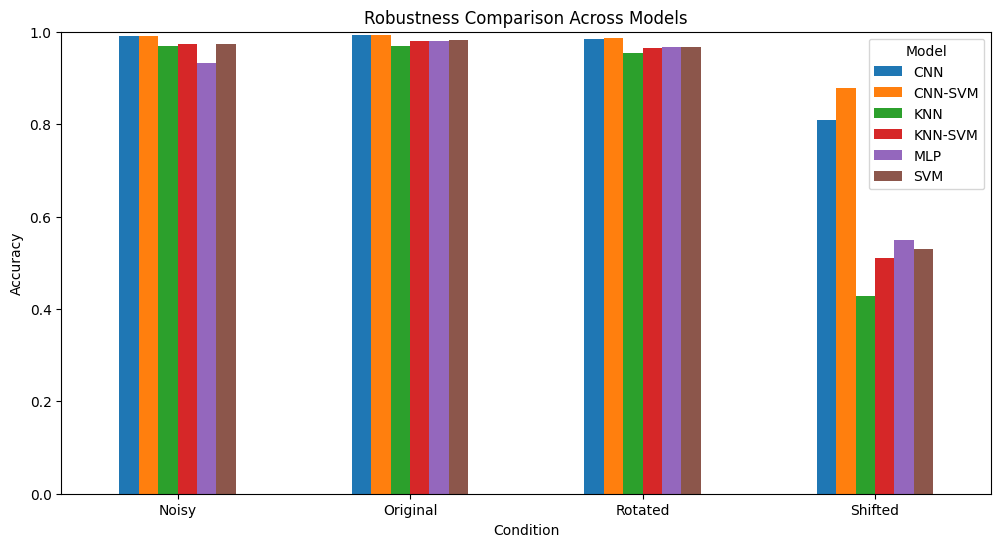

In [73]:
pivot_df = robustness_df.pivot(index="Condition", columns="Model", values="Accuracy")
pivot_df.plot(kind="bar", figsize=(12,6))
plt.title("Robustness Comparison Across Models")
plt.ylabel("Accuracy")
plt.ylim(0.0, 1.0)
plt.xticks(rotation=0)
plt.show()

## Error analysis

In [74]:
# Confusion matrix based error analysis for CNN-SVM
cm = confusion_matrix(y_test, y_test_pred_cnn_svm)
print(cm)

# Most confused digit pairs

cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

misclassified_pairs = []

for true_digit in range(10):
    for pred_digit in range(10):
        if true_digit != pred_digit and cm_no_diag[true_digit, pred_digit] > 0:
            misclassified_pairs.append({
                "True Digit": true_digit,
                "Predicted As": pred_digit,
                "Count": cm_no_diag[true_digit, pred_digit]
            })

misclassified_pairs_df = pd.DataFrame(misclassified_pairs)
misclassified_pairs_df = misclassified_pairs_df.sort_values(by="Count", ascending=False)

display(misclassified_pairs_df.head(10))

[[ 975    0    2    0    0    1    0    1    1    0]
 [   0 1135    0    0    0    0    0    0    0    0]
 [   1    0 1025    0    1    0    0    5    0    0]
 [   0    0    1 1004    0    3    0    0    2    0]
 [   0    0    0    0  976    0    1    0    2    3]
 [   2    0    0    4    0  884    1    1    0    0]
 [   3    3    0    0    1    1  949    0    1    0]
 [   0    3    5    0    0    0    0 1016    1    3]
 [   3    0    0    2    0    0    0    0  968    1]
 [   0    0    0    0    4    4    0    3    2  996]]


,True Digit,Predicted As,Count
6,2,7,5
23,7,2,5
29,9,4,4
30,9,5,4
14,5,3,4
18,6,1,3
17,6,0,3
12,4,9,3
8,3,5,3
31,9,7,3


,Digit,Error Rate
9,9,0.012884
7,7,0.011673
6,6,0.009395
5,5,0.008969
2,2,0.006783
8,8,0.006160
4,4,0.006110
3,3,0.005941
0,0,0.005102
1,1,0.000000


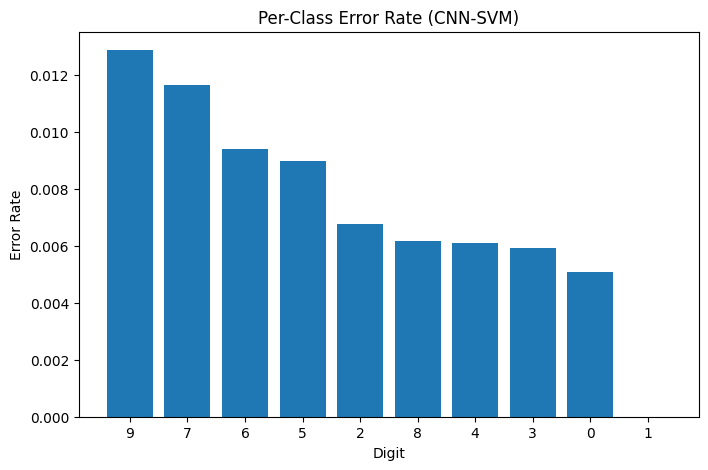

In [76]:
# Per-class error rate
per_class_total = cm.sum(axis=1)
per_class_correct = np.diag(cm)
per_class_error_rate = 1 - (per_class_correct / per_class_total)

error_rate_df = pd.DataFrame({
    "Digit": range(10),
    "Error Rate": per_class_error_rate
}).sort_values(by="Error Rate", ascending=False)

display(error_rate_df)

plt.figure(figsize=(8,5))
plt.bar(error_rate_df["Digit"].astype(str), error_rate_df["Error Rate"])
plt.title("Per-Class Error Rate (CNN-SVM)")
plt.xlabel("Digit")
plt.ylabel("Error Rate")
plt.show()

Number of misclassified samples: 72


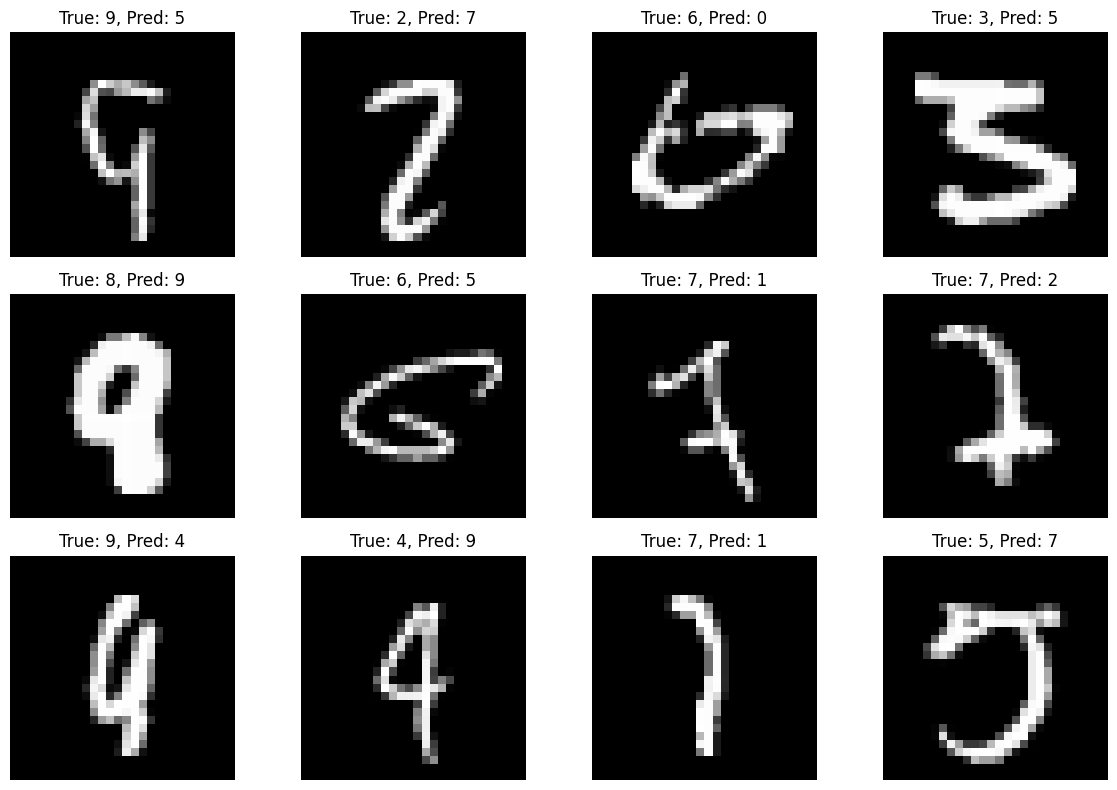

In [77]:
# misclassified examples
misclassified_idx = np.where(y_test != y_test_pred_cnn_svm)[0]
print("Number of misclassified samples:", len(misclassified_idx))

plt.figure(figsize=(12,8))

for i, idx in enumerate(misclassified_idx[:12]):
    plt.subplot(3, 4, i+1)
    plt.imshow(X_test[idx], cmap='gray')
    plt.title(f"True: {y_test[idx]}, Pred: {y_test_pred_cnn_svm[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Error summary for all models

In [78]:
def get_error_analysis_summary(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    error_rate = 1 - np.trace(cm) / np.sum(cm)

    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)
    max_pair = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)

    return {
        "Model": model_name,
        "Overall Error Rate": error_rate,
        "Most Confused Pair": f"{max_pair[0]} → {max_pair[1]}",
        "Count": cm_no_diag[max_pair]
    }

error_summary_df = pd.DataFrame([
    get_error_analysis_summary(y_test, y_test_pred_knn, "KNN"),
    get_error_analysis_summary(y_test, y_test_pred_svm, "SVM"),
    get_error_analysis_summary(y_test, y_test_pred_mlp, "MLP"),
    get_error_analysis_summary(y_test, y_test_pred_cnn, "CNN"),
    get_error_analysis_summary(y_test, y_test_pred_cnn_svm, "CNN-SVM"),
    get_error_analysis_summary(y_test, y_test_pred_knn_svm, "KNN-SVM")
])

display(error_summary_df)

,Model,Overall Error Rate,Most Confused Pair,Count
0,KNN,0.0315,7 → 1,25
1,SVM,0.0187,7 → 2,12
2,MLP,0.0193,4 → 9,15
3,CNN,0.0081,2 → 7,6
4,CNN-SVM,0.0072,2 → 7,5
5,KNN-SVM,0.0196,4 → 9,14


Error analysis was performed using confusion matrices, per-class error rates, and visual inspection of misclassified samples. This helped identify which digit pairs were most frequently confused and which classes were hardest for the models to distinguish.